# [Lab Session 4](deconvolution.ipynb)

In [87]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

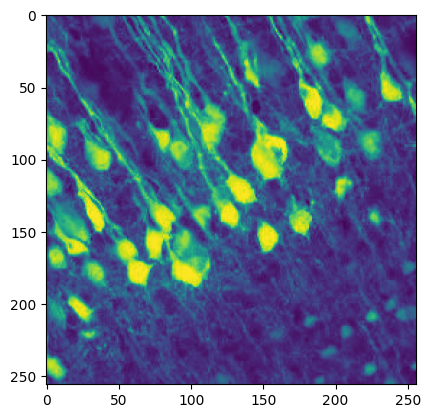

In [88]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img)

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [89]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

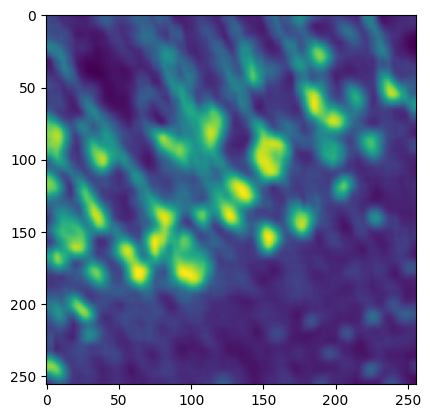

In [90]:
img_conv = conv (img, psf, mode='same',boundary='symm') 
plt.imshow(img_conv)

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

In [91]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)
psf_2 = create_psf(psf_size)

Apply the second psf to the image:

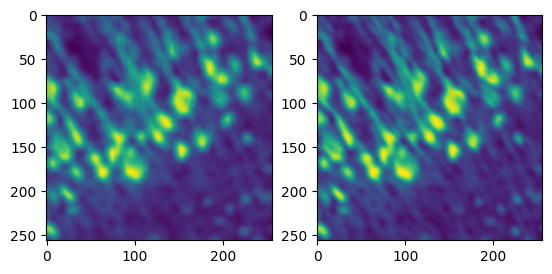

In [92]:
plt.figure()
plt.subplot(1,2,1)
img_conv = conv (img, psf, mode='same',boundary='symm') 
plt.imshow(img_conv)

plt.subplot (1,2,2)
img_conv2 = conv (img, psf_2, mode='same',boundary='symm')
plt.imshow (img_conv2)

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [ ]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    psf_flipped = np.flip(psf)
    
    for i in range (n_iterations):
        blurred = conv (img_deconv, psf, mode='same',boundary='symm')
        ratio = image / blurred
        img_deconv = img_deconv * conv (ratio, psf_flipped, mode='same',boundary='symm')
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

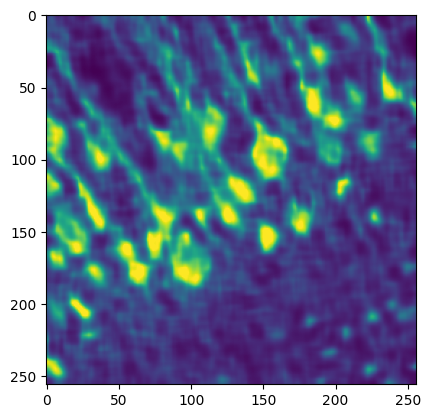

In [94]:
bild_deconv = richardson_lucy_deconvolution(img_conv, psf, 30)
plt.imshow(bild_deconv)

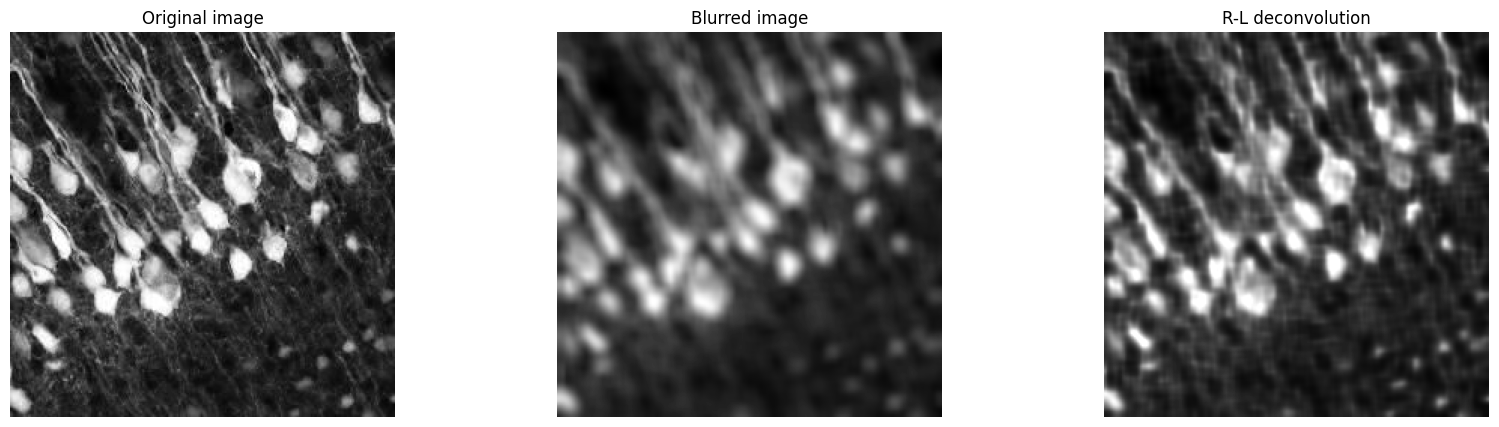

In [95]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_conv, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(bild_deconv, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [96]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 10
noise = noise / reduce_factor

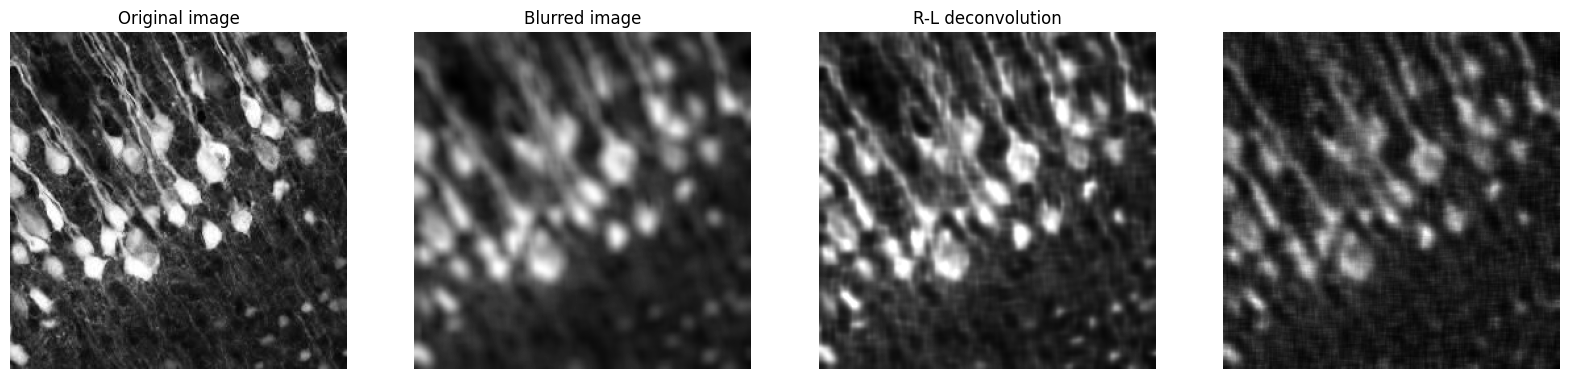

In [97]:
img_noisy = np.clip (img_conv2 + noise, 0, 1)
bild_noisy = richardson_lucy_deconvolution(img_noisy, psf, 5)

plt.figure(figsize=(20,5))
plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(img_conv, 'gray')
plt.title('Blurred image')
plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(bild_deconv, 'gray')
plt.title('R-L deconvolution')
plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(bild_noisy, 'gray')
plt.show()


**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

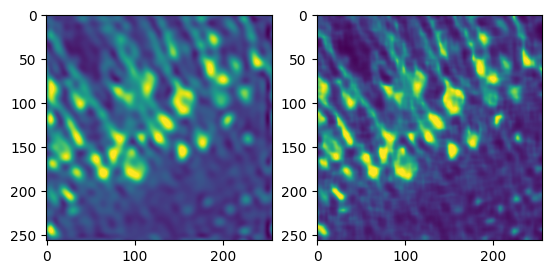

In [98]:
bild_wiener = wiener(img_conv, psf, balance=2, clip=True)
bild_deconv = richardson_lucy_deconvolution(img_conv, psf, 20)

plt.figure()
plt.subplot(1,2,1)
plt.imshow(bild_wiener)
plt.subplot (1,2,2)
plt.imshow (bild_deconv)

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

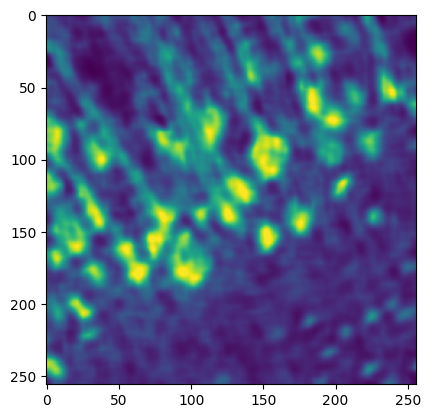

In [ ]:
psf_size = 1
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

bild_deconv_2 = richardson_lucy_deconvolution(img_conv, psf_2, 30)
plt.imshow (bild_deconv_2)

**[Task 8.]()** Use a wrong PSF to restore the image